In [1]:
# Load the final project dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cctv_data = pd.read_csv("data/cctv_demand_data.csv")

cctv_data["Date"] = pd.to_datetime(cctv_data["Date"])

print("Final CCTV dataset loaded successfully!")
print("Shape:", cctv_data.shape)
print("Start Date:", cctv_data["Date"].min())
print("End Date:", cctv_data["Date"].max())

cctv_data.head()

Final CCTV dataset loaded successfully!
Shape: (13149, 4)
Start Date: 2022-01-01 00:00:00
End Date: 2025-12-31 00:00:00


,Date,Product,Units_Sold,Support_Requests
0,2022-01-01,2MP CCTV Camera,6,3
1,2022-01-01,5MP CCTV Camera,8,2
2,2022-01-01,IP Camera,7,1
3,2022-01-01,DVR 8 Channel,5,1
4,2022-01-01,NVR 8 Channel,1,1


In [2]:
import os

# Create the data folder if it doesn't exist
os.makedirs("data", exist_ok=True)

# Save the dataset
cctv_data.to_csv("data/cctv_demand_data.csv", index=False)

print("Dataset saved successfully!")
print("Rows:", len(cctv_data))
print("Columns:", len(cctv_data.columns))

Dataset saved successfully!
Rows: 13149
Columns: 4


In [3]:
# Check the dataset structure

print("Dataset Shape:")
print(cctv_data.shape)

print("\nColumn Names:")
print(cctv_data.columns.tolist())

print("\nData Types:")
print(cctv_data.dtypes)

print("\nMissing Values:")
print(cctv_data.isnull().sum())

Dataset Shape:
(13149, 4)

Column Names:
['Date', 'Product', 'Units_Sold', 'Support_Requests']

Data Types:
Date                datetime64[ns]
Product                     object
Units_Sold                   int64
Support_Requests             int64
dtype: object

Missing Values:
Date                0
Product             0
Units_Sold          0
Support_Requests    0
dtype: int64


In [4]:
# Display the first 10 records

cctv_data.head(10)

,Date,Product,Units_Sold,Support_Requests
0,2022-01-01,2MP CCTV Camera,6,3
1,2022-01-01,5MP CCTV Camera,8,2
2,2022-01-01,IP Camera,7,1
3,2022-01-01,DVR 8 Channel,5,1
4,2022-01-01,NVR 8 Channel,1,1
5,2022-01-01,1TB Hard Disk,9,2
6,2022-01-01,Power Supply,3,1
7,2022-01-01,Network Switch,4,2
8,2022-01-01,CCTV Cable,12,3
9,2022-01-02,2MP CCTV Camera,9,5


In [5]:
# Display the last 10 records

cctv_data.tail(10)

,Date,Product,Units_Sold,Support_Requests
13139,2025-12-30,CCTV Cable,6,0
13140,2025-12-31,2MP CCTV Camera,11,3
13141,2025-12-31,5MP CCTV Camera,6,4
13142,2025-12-31,IP Camera,9,3
13143,2025-12-31,DVR 8 Channel,5,2
13144,2025-12-31,NVR 8 Channel,4,3
13145,2025-12-31,1TB Hard Disk,2,1
13146,2025-12-31,Power Supply,6,3
13147,2025-12-31,Network Switch,3,0
13148,2025-12-31,CCTV Cable,4,0


In [6]:
# Calculate total demand for each product

product_demand = (
    cctv_data
    .groupby("Product")["Units_Sold"]
    .sum()
    .sort_values(ascending=False)
)

product_demand

Product
CCTV Cable         14731
5MP CCTV Camera    11707
IP Camera          11568
2MP CCTV Camera    11538
Power Supply        8808
Network Switch      8682
1TB Hard Disk       7385
DVR 8 Channel       5941
NVR 8 Channel       5932
Name: Units_Sold, dtype: int64

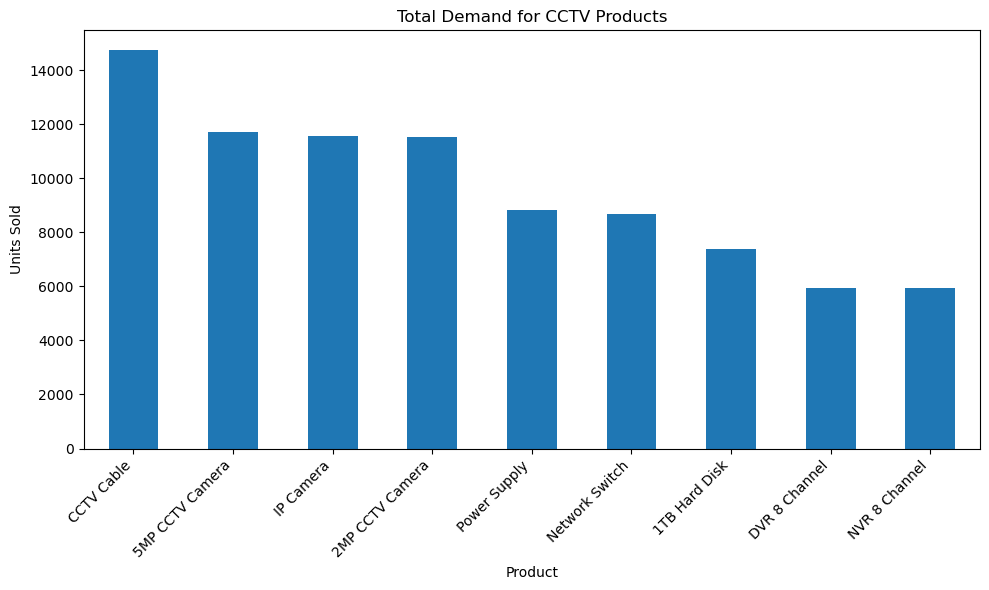

In [7]:
import matplotlib.pyplot as plt

# Plot total demand by product

plt.figure(figsize=(10, 6))

product_demand.plot(kind="bar")

plt.title("Total Demand for CCTV Products")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [8]:
# Convert Date column to datetime

cctv_data["Date"] = pd.to_datetime(cctv_data["Date"])

# Calculate total daily demand

daily_demand = (
    cctv_data
    .groupby("Date")["Units_Sold"]
    .sum()
)

daily_demand.head()

Date
2022-01-01    55
2022-01-02    52
2022-01-03    59
2022-01-04    45
2022-01-05    54
Name: Units_Sold, dtype: int64

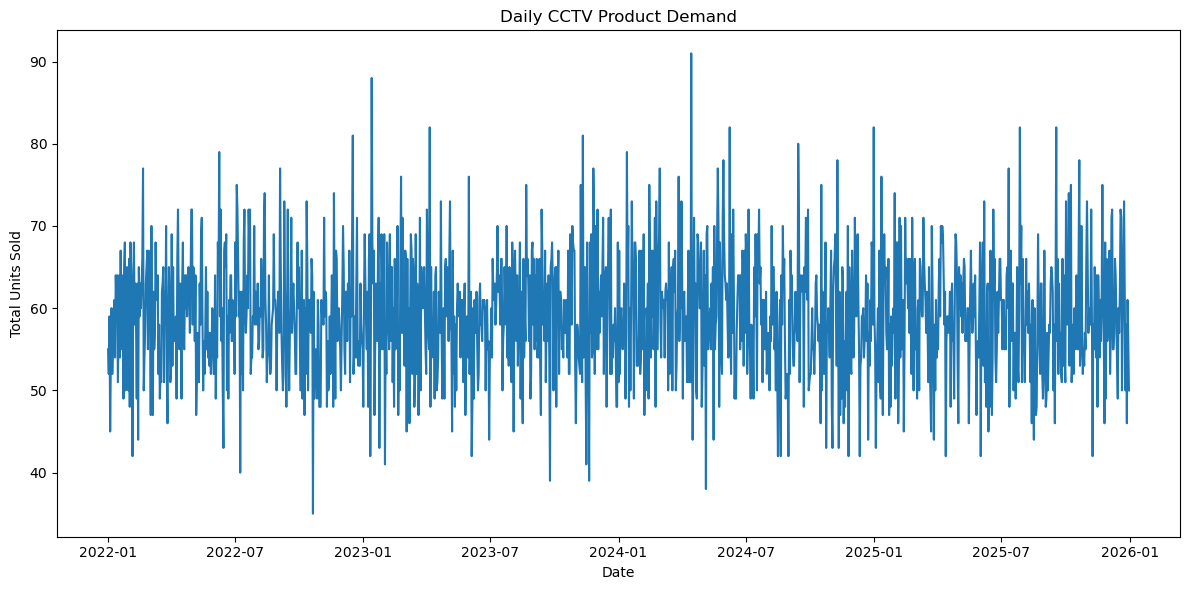

In [9]:
import matplotlib.pyplot as plt

# Plot daily CCTV demand

plt.figure(figsize=(12, 6))

plt.plot(daily_demand)

plt.title("Daily CCTV Product Demand")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

In [10]:
# Create monthly demand

monthly_demand = (
    cctv_data
    .set_index("Date")
    .resample("ME")["Units_Sold"]
    .sum()
)

monthly_demand.head()

Date
2022-01-31    1792
2022-02-28    1680
2022-03-31    1791
2022-04-30    1812
2022-05-31    1803
Freq: ME, Name: Units_Sold, dtype: int64

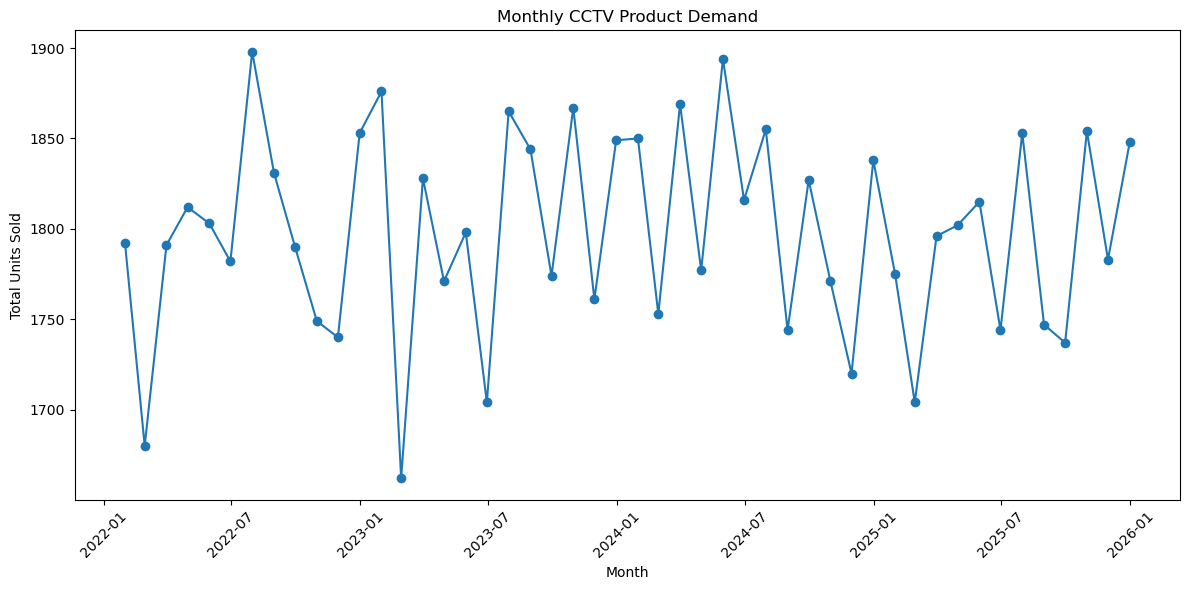

In [11]:
# Plot monthly demand

plt.figure(figsize=(12, 6))

plt.plot(monthly_demand, marker="o")

plt.title("Monthly CCTV Product Demand")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Basic statistics of monthly demand

print("Minimum monthly demand:", monthly_demand.min())
print("Maximum monthly demand:", monthly_demand.max())
print("Average monthly demand:", round(monthly_demand.mean(), 2))
print("Total demand:", monthly_demand.sum())

Minimum monthly demand: 1662
Maximum monthly demand: 1898
Average monthly demand: 1797.75
Total demand: 86292


In [13]:
# Display all monthly demand values

monthly_demand


Date
2022-01-31    1792
2022-02-28    1680
2022-03-31    1791
2022-04-30    1812
2022-05-31    1803
2022-06-30    1782
2022-07-31    1898
2022-08-31    1831
2022-09-30    1790
2022-10-31    1749
2022-11-30    1740
2022-12-31    1853
2023-01-31    1876
2023-02-28    1662
2023-03-31    1828
2023-04-30    1771
2023-05-31    1798
2023-06-30    1704
2023-07-31    1865
2023-08-31    1844
2023-09-30    1774
2023-10-31    1867
2023-11-30    1761
2023-12-31    1849
2024-01-31    1850
2024-02-29    1753
2024-03-31    1869
2024-04-30    1777
2024-05-31    1894
2024-06-30    1816
2024-07-31    1855
2024-08-31    1744
2024-09-30    1827
2024-10-31    1771
2024-11-30    1720
2024-12-31    1838
2025-01-31    1775
2025-02-28    1704
2025-03-31    1796
2025-04-30    1802
2025-05-31    1815
2025-06-30    1744
2025-07-31    1853
2025-08-31    1747
2025-09-30    1737
2025-10-31    1854
2025-11-30    1783
2025-12-31    1848
Freq: ME, Name: Units_Sold, dtype: int64

In [14]:
# Calculate average demand by month

monthly_seasonality = (
    cctv_data
    .assign(Month=cctv_data["Date"].dt.month)
    .groupby("Month")["Units_Sold"]
    .mean()
)

monthly_seasonality

Month
1     6.534946
2     6.685349
3     6.526882
4     6.631481
5     6.550179
6     6.524074
7     6.694444
8     6.421147
9     6.600000
10    6.488351
11    6.485185
12    6.620072
Name: Units_Sold, dtype: float64

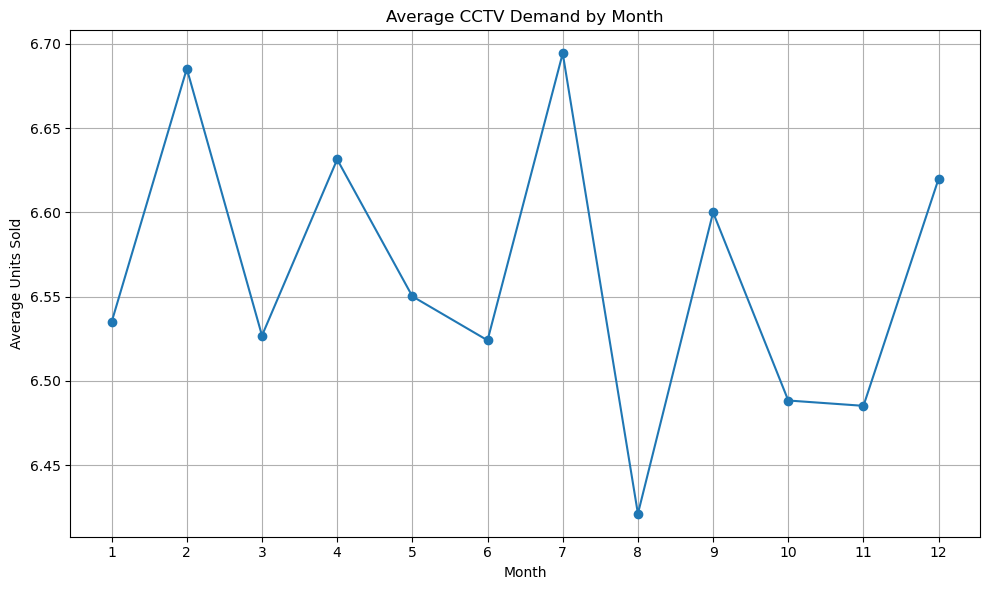

In [15]:
# Plot average demand by month

plt.figure(figsize=(10, 6))

plt.plot(
    monthly_seasonality.index,
    monthly_seasonality.values,
    marker="o"
)

plt.title("Average CCTV Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")

plt.xticks(range(1, 13))
plt.grid(True)

plt.tight_layout()
plt.show()

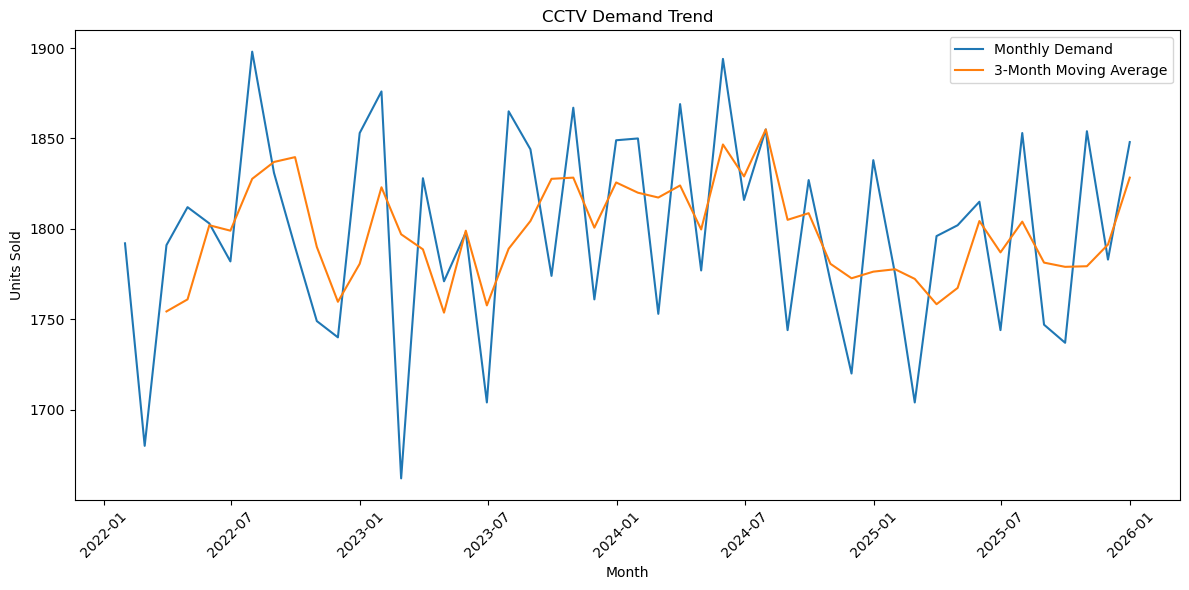

In [16]:
# Calculate a 3-month moving average

moving_average = monthly_demand.rolling(window=3).mean()

plt.figure(figsize=(12, 6))

plt.plot(monthly_demand, label="Monthly Demand")
plt.plot(moving_average, label="3-Month Moving Average")

plt.title("CCTV Demand Trend")
plt.xlabel("Month")
plt.ylabel("Units Sold")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
# Prepare monthly demand for forecasting

forecast_data = monthly_demand.copy()

# Make sure dates are sorted
forecast_data = forecast_data.sort_index()

# Check for missing values
print("Missing values:", forecast_data.isnull().sum())

# Display the forecasting data
forecast_data.head()

Missing values: 0


Date
2022-01-31    1792
2022-02-28    1680
2022-03-31    1791
2022-04-30    1812
2022-05-31    1803
Freq: ME, Name: Units_Sold, dtype: int64

In [18]:
# Check the complete forecasting period

print("Start date:", forecast_data.index.min())
print("End date:", forecast_data.index.max())
print("Number of months:", len(forecast_data))

Start date: 2022-01-31 00:00:00
End date: 2025-12-31 00:00:00
Number of months: 48


In [19]:
# Split the data into training and testing sets

train_data = forecast_data[forecast_data.index.year == 2024]
test_data = forecast_data[forecast_data.index.year == 2025]

print("Training data:")
print(train_data)

print("\nTesting data:")
print(test_data)

Training data:
Date
2024-01-31    1850
2024-02-29    1753
2024-03-31    1869
2024-04-30    1777
2024-05-31    1894
2024-06-30    1816
2024-07-31    1855
2024-08-31    1744
2024-09-30    1827
2024-10-31    1771
2024-11-30    1720
2024-12-31    1838
Freq: ME, Name: Units_Sold, dtype: int64

Testing data:
Date
2025-01-31    1775
2025-02-28    1704
2025-03-31    1796
2025-04-30    1802
2025-05-31    1815
2025-06-30    1744
2025-07-31    1853
2025-08-31    1747
2025-09-30    1737
2025-10-31    1854
2025-11-30    1783
2025-12-31    1848
Freq: ME, Name: Units_Sold, dtype: int64


In [20]:
print("Training months:", len(train_data))
print("Testing months:", len(test_data))

Training months: 12
Testing months: 12


In [21]:
from statsmodels.tsa.arima.model import ARIMA

print("ARIMA imported successfully!")

ARIMA imported successfully!


In [22]:
# Train ARIMA model

model = ARIMA(train_data, order=(1, 1, 1))

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Units_Sold   No. Observations:                   12
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -58.950
Date:                Sat, 03 Oct 2026   AIC                            123.899
Time:                        23:50:41   BIC                            125.093
Sample:                    01-31-2024   HQIC                           123.147
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7826      0.387     -2.022      0.043      -1.541      -0.024
ma.L1         -0.2702      0.502     -0.538      0.590      -1.254       0.714
sigma2      2377.2496   1203.691      1.975      0.0

In [23]:
# Predict demand for the testing period

predictions = model_fit.forecast(steps=len(test_data))

print(predictions)

2025-01-31    1731.439911
2025-02-28    1814.837703
2025-03-31    1749.567565
2025-04-30    1800.650344
2025-05-31    1760.671108
2025-06-30    1791.960308
2025-07-31    1767.472245
2025-08-31    1786.637492
2025-09-30    1771.638074
2025-10-31    1783.377163
2025-11-30    1774.189726
2025-12-31    1781.380147
Freq: ME, Name: predicted_mean, dtype: float64


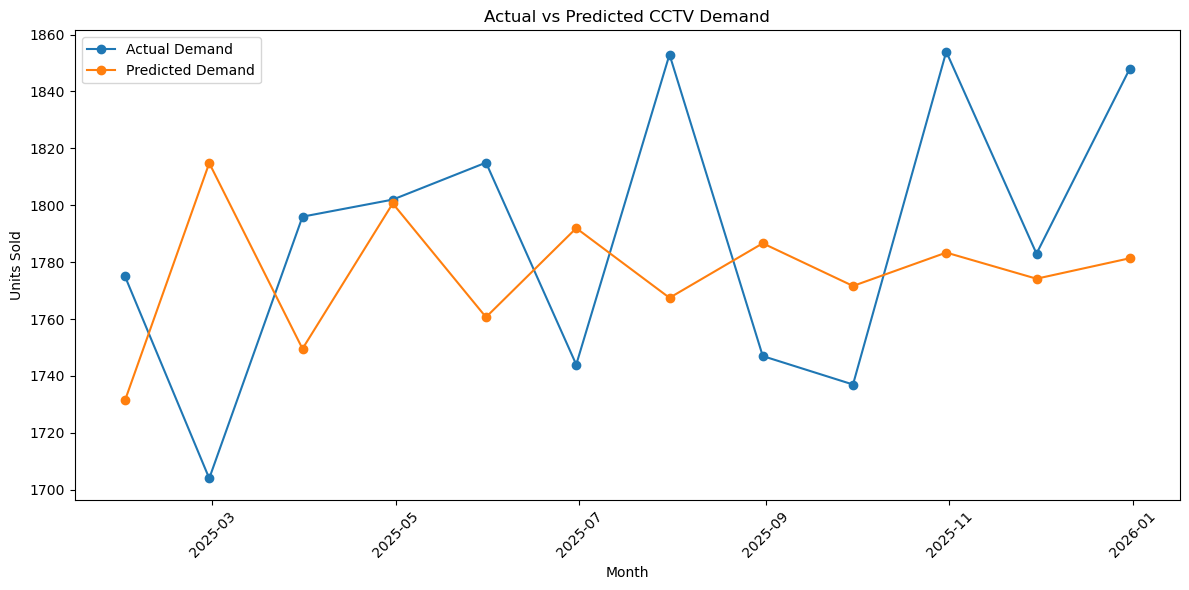

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(test_data.index, test_data.values, marker="o", label="Actual Demand")
plt.plot(test_data.index, predictions, marker="o", label="Predicted Demand")

plt.title("Actual vs Predicted CCTV Demand")
plt.xlabel("Month")
plt.ylabel("Units Sold")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics

mae = mean_absolute_error(test_data, predictions)

rmse = np.sqrt(
    mean_squared_error(test_data, predictions)
)

mape = np.mean(
    np.abs((test_data.values - predictions) / test_data.values)
) * 100

print("Model Evaluation")
print("-----------------")
print("MAE  :", round(mae, 2))
print("RMSE :", round(rmse, 2))
print("MAPE :", round(mape, 2), "%")

Model Evaluation
-----------------
MAE  : 50.86
RMSE : 58.58
MAPE : 2.85 %


In [26]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

print("SARIMA imported successfully!")

SARIMA imported successfully!


In [27]:
# Train SARIMA model

sarima_model = SARIMAX(
    train_data,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

print("SARIMA model trained successfully!")

SARIMA model trained successfully!


C:\Users\dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
C:\Users\dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


In [28]:
dates = pd.date_range(
    start="2022-01-01",
    end="2025-12-31",
    freq="D"
)

print("Start:", dates.min())
print("End:", dates.max())
print("Number of days:", len(dates))

Start: 2022-01-01 00:00:00
End: 2025-12-31 00:00:00
Number of days: 1461


In [29]:
# Generate the 4-year CCTV company dataset

np.random.seed(42)

products = [
    "2MP CCTV Camera",
    "5MP CCTV Camera",
    "IP Camera",
    "DVR 8 Channel",
    "NVR 8 Channel",
    "1TB Hard Disk",
    "Power Supply",
    "Network Switch",
    "CCTV Cable"
]

data = []

for date in dates:
    for product in products:

        if "Camera" in product:
            base_demand = 8
        elif "DVR" in product or "NVR" in product:
            base_demand = 4
        elif "Hard Disk" in product:
            base_demand = 5
        elif "Cable" in product:
            base_demand = 10
        else:
            base_demand = 6

        demand = np.random.poisson(base_demand)

        support_requests = np.random.poisson(
            max(1, demand * 0.4)
        )

        data.append([
            date,
            product,
            demand,
            support_requests
        ])

cctv_data = pd.DataFrame(
    data,
    columns=[
        "Date",
        "Product",
        "Units_Sold",
        "Support_Requests"
    ]
)

print("Dataset created successfully!")
print("Rows:", len(cctv_data))
print("Columns:", len(cctv_data.columns))

Dataset created successfully!
Rows: 13149
Columns: 4


In [30]:
cctv_data.to_csv(
    "data/cctv_demand_data.csv",
    index=False
)

print("4-year dataset saved successfully!")

4-year dataset saved successfully!


In [31]:
# Make sure Date is a datetime column

cctv_data["Date"] = pd.to_datetime(cctv_data["Date"])

In [32]:
# Calculate total monthly CCTV demand

monthly_demand = (
    cctv_data
    .set_index("Date")
    .resample("ME")["Units_Sold"]
    .sum()
)

print("Number of months:", len(monthly_demand))
print("\nFirst 5 months:")
print(monthly_demand.head())

Number of months: 48

First 5 months:
Date
2022-01-31    1792
2022-02-28    1680
2022-03-31    1791
2022-04-30    1812
2022-05-31    1803
Freq: ME, Name: Units_Sold, dtype: int64


In [33]:
# Prepare forecasting data

forecast_data = monthly_demand.sort_index()

print("Start:", forecast_data.index.min())
print("End:", forecast_data.index.max())
print("Total months:", len(forecast_data))

Start: 2022-01-31 00:00:00
End: 2025-12-31 00:00:00
Total months: 48


In [34]:
# Split data into training and testing sets

train_data = forecast_data[
    forecast_data.index.year <= 2024
]

test_data = forecast_data[
    forecast_data.index.year == 2025
]

print("Training period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting period:")
print(test_data.index.min(), "to", test_data.index.max())

print("\nTraining months:", len(train_data))
print("Testing months:", len(test_data))

Training period:
2022-01-31 00:00:00 to 2024-12-31 00:00:00

Testing period:
2025-01-31 00:00:00 to 2025-12-31 00:00:00

Training months: 36
Testing months: 12


In [35]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Train the SARIMA model

sarima_model = SARIMAX(
    train_data,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

print("SARIMA model trained successfully!")

C:\Users\dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


SARIMA model trained successfully!


In [36]:
# Forecast the 12 months of 2025

sarima_predictions = sarima_fit.forecast(
    steps=len(test_data)
)

print("2025 Forecast:")
print(sarima_predictions)

2025 Forecast:
2025-01-31    1865.499939
2025-02-28    1661.665656
2025-03-31    1818.424164
2025-04-30    1799.544788
2025-05-31    1790.904621
2025-06-30    1720.878585
2025-07-31    1893.740857
2025-08-31    1877.339128
2025-09-30    1781.825706
2025-10-31    1860.072448
2025-11-30    1777.653487
2025-12-31    1865.666927
Freq: ME, Name: predicted_mean, dtype: float64


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate SARIMA evaluation metrics

sarima_mae = mean_absolute_error(
    test_data,
    sarima_predictions
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test_data,
        sarima_predictions
    )
)

sarima_mape = np.mean(
    np.abs(
        (test_data.values - sarima_predictions)
        / test_data.values
    )
) * 100

print("SARIMA Model Evaluation")
print("-----------------------")
print("MAE  :", round(sarima_mae, 2))
print("RMSE :", round(sarima_rmse, 2))
print("MAPE :", round(sarima_mape, 2), "%")

SARIMA Model Evaluation
-----------------------
MAE  : 37.49
RMSE : 52.15
MAPE : 2.12 %


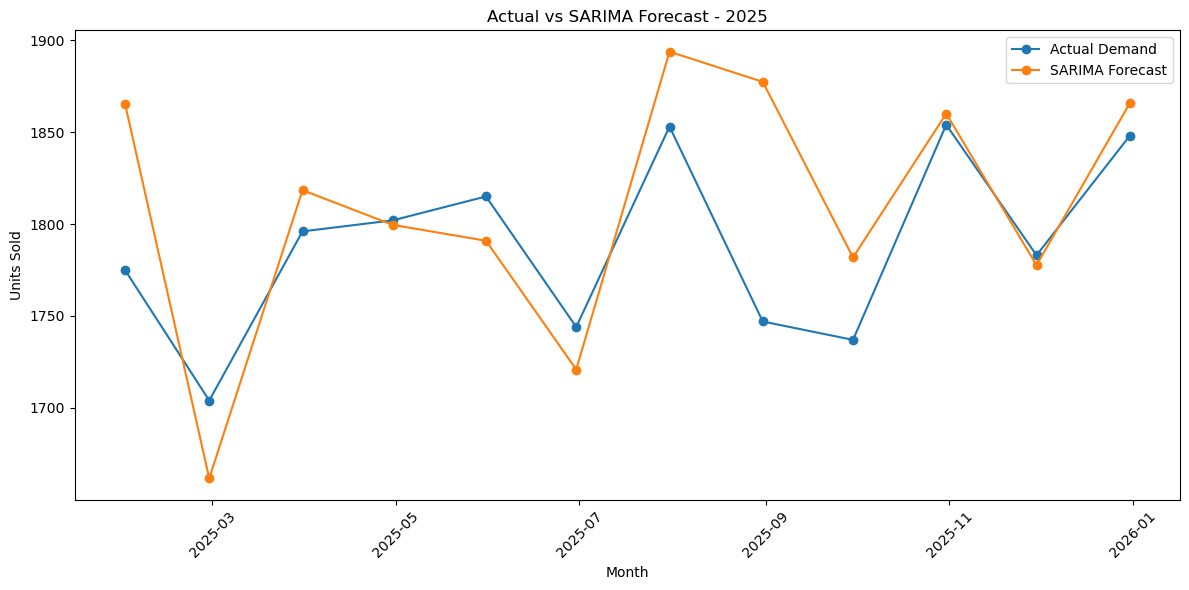

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    test_data.index,
    test_data.values,
    marker="o",
    label="Actual Demand"
)

plt.plot(
    test_data.index,
    sarima_predictions,
    marker="o",
    label="SARIMA Forecast"
)

plt.title("Actual vs SARIMA Forecast - 2025")
plt.xlabel("Month")
plt.ylabel("Units Sold")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
# Evaluate the ARIMA model on the 2025 test data

arima_mae = mean_absolute_error(
    test_data,
    predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test_data,
        predictions
    )
)

arima_mape = np.mean(
    np.abs(
        (test_data.values - predictions)
        / test_data.values
    )
) * 100

print("ARIMA")
print("MAE :", round(arima_mae, 2))
print("RMSE:", round(arima_rmse, 2))
print("MAPE:", round(arima_mape, 2), "%")

ARIMA
MAE : 50.86
RMSE: 58.58
MAPE: 2.85 %


In [40]:
# Compare both forecasting models

model_comparison = pd.DataFrame({
    "Model": ["ARIMA", "SARIMA"],
    "MAE": [arima_mae, sarima_mae],
    "RMSE": [arima_rmse, sarima_rmse],
    "MAPE (%)": [arima_mape, sarima_mape]
})

model_comparison

,Model,MAE,RMSE,MAPE (%)
0,ARIMA,50.860447,58.581442,2.845766
1,SARIMA,37.493503,52.154837,2.120380


In [41]:
# Train the final SARIMA model using all available historical data

final_model = SARIMAX(
    forecast_data,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_fit = final_model.fit(disp=False)

print("Final SARIMA model trained successfully!")

C:\Users\dell\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


Final SARIMA model trained successfully!


In [42]:
# Forecast the next 12 months

future_forecast = final_fit.forecast(steps=12)

print("Forecast for the next 12 months:")
print(future_forecast)

Forecast for the next 12 months:
2026-01-31    1823.223198
2026-02-28    1731.163218
2026-03-31    1840.837477
2026-04-30    1782.308832
2026-05-31    1862.119353
2026-06-30    1786.002468
2026-07-31    1851.950644
2026-08-31    1745.485579
2026-09-30    1792.935876
2026-10-31    1798.485728
2026-11-30    1739.249453
2026-12-31    1838.882917
Freq: ME, Name: predicted_mean, dtype: float64


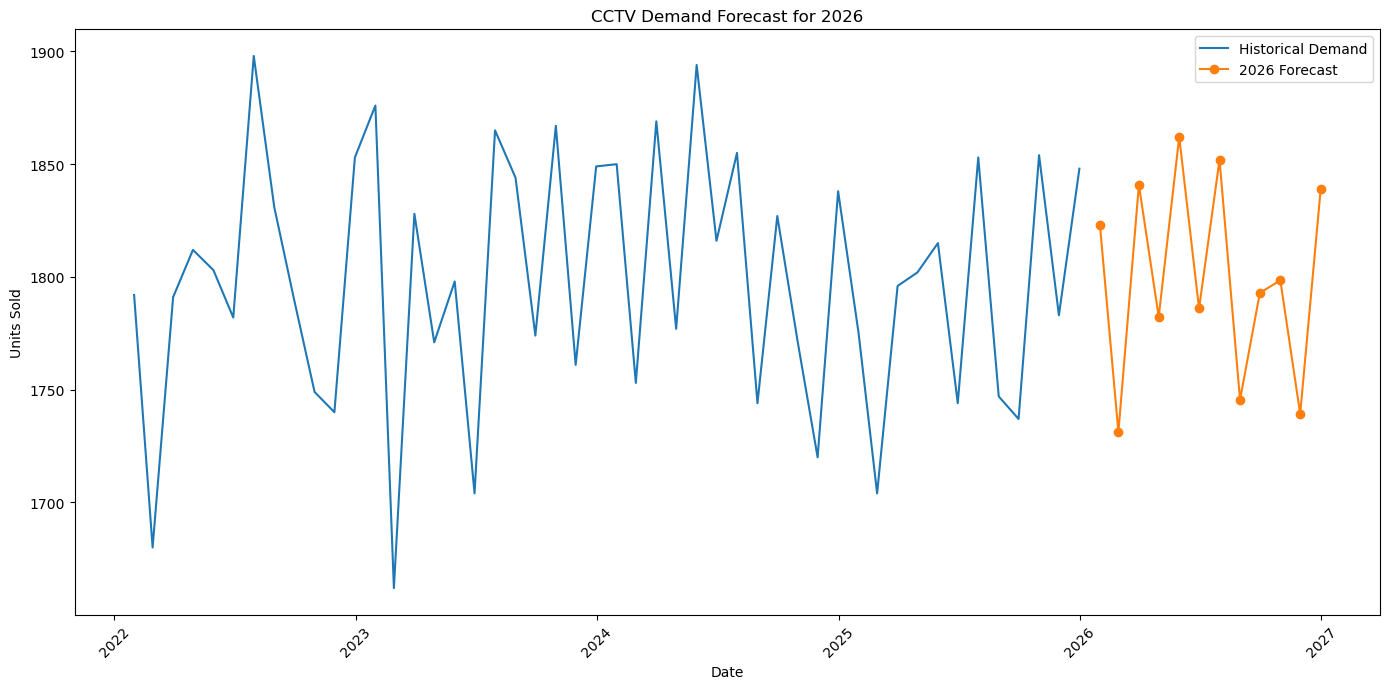

In [43]:
# Create future dates for the forecast

future_dates = pd.date_range(
    start="2026-01-31",
    periods=12,
    freq="ME"
)

# Plot historical demand and 2026 forecast

plt.figure(figsize=(14, 7))

plt.plot(
    forecast_data.index,
    forecast_data.values,
    label="Historical Demand"
)

plt.plot(
    future_dates,
    future_forecast.values,
    marker="o",
    label="2026 Forecast"
)

plt.title("CCTV Demand Forecast for 2026")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [44]:
# Create a forecast table

forecast_table = pd.DataFrame({
    "Month": future_dates,
    "Predicted_Demand": future_forecast.values
})

forecast_table["Predicted_Demand"] = (
    forecast_table["Predicted_Demand"]
    .round()
    .astype(int)
)

forecast_table

,Month,Predicted_Demand
0,2026-01-31,1823
1,2026-02-28,1731
2,2026-03-31,1841
3,2026-04-30,1782
4,2026-05-31,1862
5,2026-06-30,1786
6,2026-07-31,1852
7,2026-08-31,1745
8,2026-09-30,1793
9,2026-10-31,1798


In [45]:
# Calculate total predicted demand for 2026

total_2026_demand = forecast_table["Predicted_Demand"].sum()

print("Total predicted CCTV demand for 2026:", total_2026_demand)

Total predicted CCTV demand for 2026: 21591


In [46]:
forecast_table.to_csv(
    "data/forecast_2026.csv",
    index=False
)

print("2026 forecast saved successfully!")

2026 forecast saved successfully!


In [47]:
forecast_table["Safety_Stock"] = (
    forecast_table["Predicted_Demand"] * 0.10
).round().astype(int)

forecast_table["Recommended_Stock"] = (
    forecast_table["Predicted_Demand"]
    + forecast_table["Safety_Stock"]
)

forecast_table

,Month,Predicted_Demand,Safety_Stock,Recommended_Stock
0,2026-01-31,1823,182,2005
1,2026-02-28,1731,173,1904
2,2026-03-31,1841,184,2025
3,2026-04-30,1782,178,1960
4,2026-05-31,1862,186,2048
5,2026-06-30,1786,179,1965
6,2026-07-31,1852,185,2037
7,2026-08-31,1745,174,1919
8,2026-09-30,1793,179,1972
9,2026-10-31,1798,180,1978


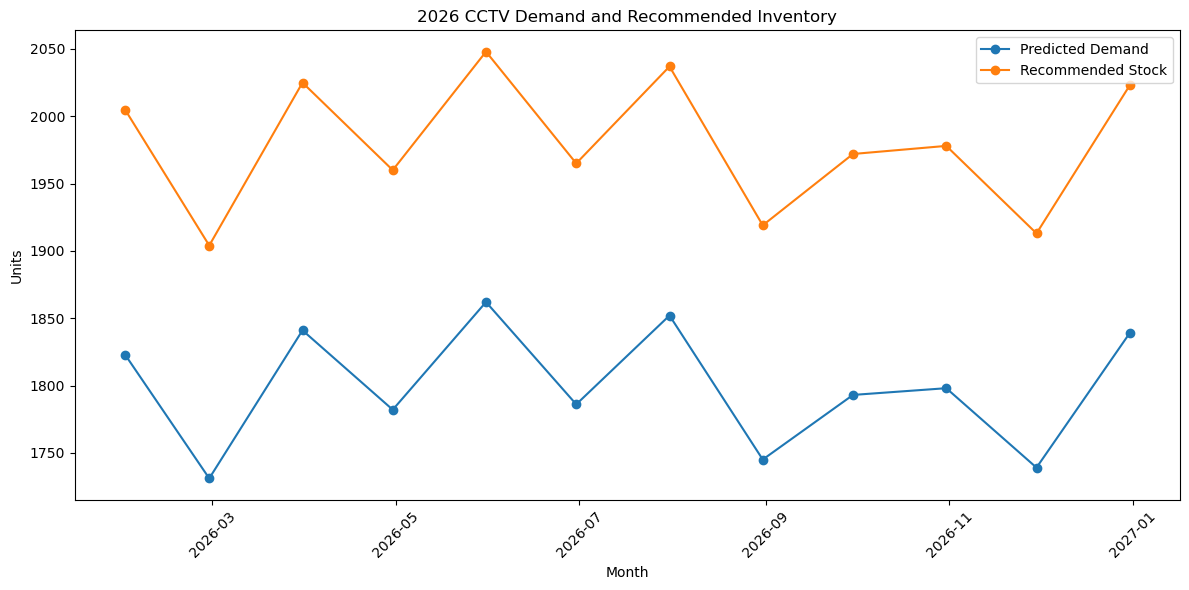

In [48]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_table["Month"],
    forecast_table["Predicted_Demand"],
    marker="o",
    label="Predicted Demand"
)

plt.plot(
    forecast_table["Month"],
    forecast_table["Recommended_Stock"],
    marker="o",
    label="Recommended Stock"
)

plt.title("2026 CCTV Demand and Recommended Inventory")
plt.xlabel("Month")
plt.ylabel("Units")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [49]:
total_predicted = forecast_table["Predicted_Demand"].sum()
total_safety_stock = forecast_table["Safety_Stock"].sum()
total_recommended = forecast_table["Recommended_Stock"].sum()

print("2026 Inventory Summary")
print("----------------------")
print("Total Predicted Demand:", total_predicted)
print("Total Safety Stock:", total_safety_stock)
print("Total Recommended Stock:", total_recommended)

2026 Inventory Summary
----------------------
Total Predicted Demand: 21591
Total Safety Stock: 2158
Total Recommended Stock: 23749


In [50]:
forecast_table.to_csv(
    "data/inventory_recommendation_2026.csv",
    index=False
)

print("Inventory recommendation saved successfully!")

Inventory recommendation saved successfully!


In [51]:
import os

print("Files in data folder:")
print(os.listdir("data"))

Files in data folder:
['.ipynb_checkpoints', 'cctv_demand_data.csv', 'final_project_summary.csv', 'forecast_2026.csv', 'inventory_recommendation_2026.csv', 'product_inventory_recommendation.csv']


In [52]:
product_summary = (
    cctv_data
    .groupby("Product")["Units_Sold"]
    .sum()
    .sort_values(ascending=False)
)

print("Product-wise Total Demand")
print("-------------------------")
print(product_summary)

Product-wise Total Demand
-------------------------
Product
CCTV Cable         14731
5MP CCTV Camera    11707
IP Camera          11568
2MP CCTV Camera    11538
Power Supply        8808
Network Switch      8682
1TB Hard Disk       7385
DVR 8 Channel       5941
NVR 8 Channel       5932
Name: Units_Sold, dtype: int64


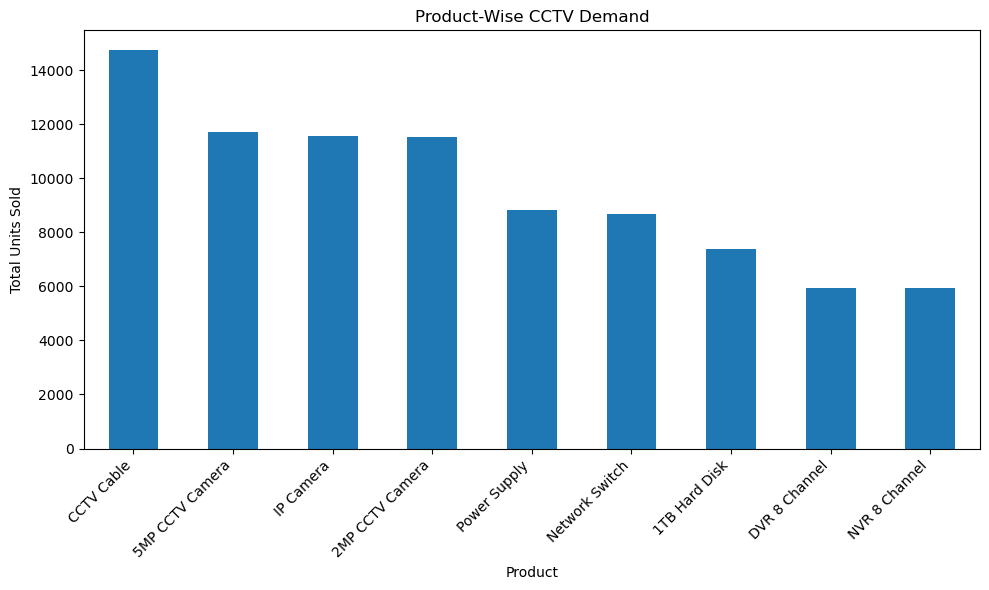

In [53]:
plt.figure(figsize=(10, 6))

product_summary.plot(kind="bar")

plt.title("Product-Wise CCTV Demand")
plt.xlabel("Product")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [54]:
product_monthly = (
    cctv_data
    .set_index("Date")
    .groupby("Product")["Units_Sold"]
    .resample("ME")
    .sum()
)

product_avg_monthly = (
    product_monthly
    .groupby("Product")
    .mean()
    .round(0)
    .astype(int)
    .sort_values(ascending=False)
)

print("Average Monthly Demand by Product")
print("---------------------------------")
print(product_avg_monthly)

Average Monthly Demand by Product
---------------------------------
Product
CCTV Cable         307
5MP CCTV Camera    244
IP Camera          241
2MP CCTV Camera    240
Power Supply       184
Network Switch     181
1TB Hard Disk      154
DVR 8 Channel      124
NVR 8 Channel      124
Name: Units_Sold, dtype: int64


In [55]:
product_inventory = pd.DataFrame({
    "Product": product_avg_monthly.index,
    "Average_Monthly_Demand": product_avg_monthly.values
})

product_inventory["Safety_Stock"] = (
    product_inventory["Average_Monthly_Demand"] * 0.10
).round().astype(int)

product_inventory["Recommended_Stock"] = (
    product_inventory["Average_Monthly_Demand"]
    + product_inventory["Safety_Stock"]
)

product_inventory

,Product,Average_Monthly_Demand,Safety_Stock,Recommended_Stock
0,CCTV Cable,307,31,338
1,5MP CCTV Camera,244,24,268
2,IP Camera,241,24,265
3,2MP CCTV Camera,240,24,264
4,Power Supply,184,18,202
5,Network Switch,181,18,199
6,1TB Hard Disk,154,15,169
7,DVR 8 Channel,124,12,136
8,NVR 8 Channel,124,12,136


In [56]:
product_inventory.to_csv(
    "data/product_inventory_recommendation.csv",
    index=False
)

print("Product-wise inventory recommendation saved successfully!")

Product-wise inventory recommendation saved successfully!


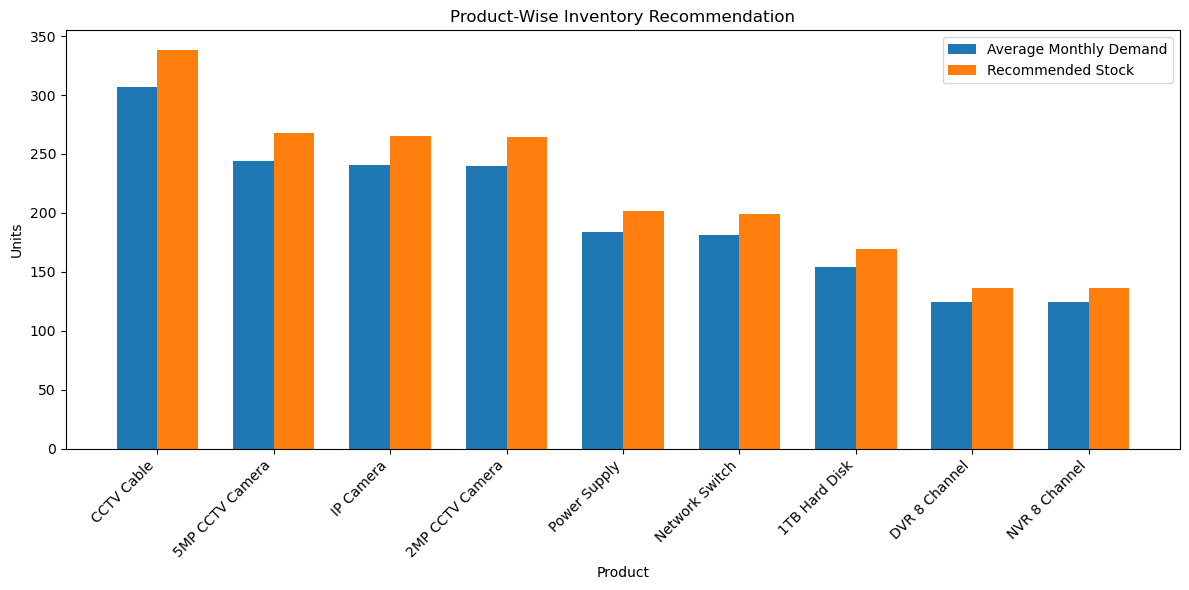

In [57]:
plt.figure(figsize=(12, 6))

x = np.arange(len(product_inventory))
width = 0.35

plt.bar(
    x - width / 2,
    product_inventory["Average_Monthly_Demand"],
    width,
    label="Average Monthly Demand"
)

plt.bar(
    x + width / 2,
    product_inventory["Recommended_Stock"],
    width,
    label="Recommended Stock"
)

plt.title("Product-Wise Inventory Recommendation")
plt.xlabel("Product")
plt.ylabel("Units")
plt.xticks(
    x,
    product_inventory["Product"],
    rotation=45,
    ha="right"
)
plt.legend()
plt.tight_layout()
plt.show()

In [58]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(
    train_data,
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

arima_predictions = arima_fit.forecast(
    steps=len(test_data)
)

print("ARIMA forecasting completed!")

ARIMA forecasting completed!


In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

arima_mae = mean_absolute_error(
    test_data,
    arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test_data,
        arima_predictions
    )
)

arima_mape = np.mean(
    np.abs(
        (test_data.values - arima_predictions.values)
        / test_data.values
    )
) * 100

print("ARIMA Model Evaluation")
print("----------------------")
print("MAE  :", round(arima_mae, 2))
print("RMSE :", round(arima_rmse, 2))
print("MAPE :", round(arima_mape, 2), "%")

ARIMA Model Evaluation
----------------------
MAE  : 40.05
RMSE : 48.74
MAPE : 2.26 %


In [60]:
model_comparison = pd.DataFrame({
    "Model": ["ARIMA", "SARIMA"],
    "MAE": [arima_mae, 37.49],
    "RMSE": [arima_rmse, 52.15],
    "MAPE": [arima_mape, 2.12]
})

model_comparison

,Model,MAE,RMSE,MAPE
0,ARIMA,40.051453,48.737578,2.259021
1,SARIMA,37.490000,52.150000,2.120000


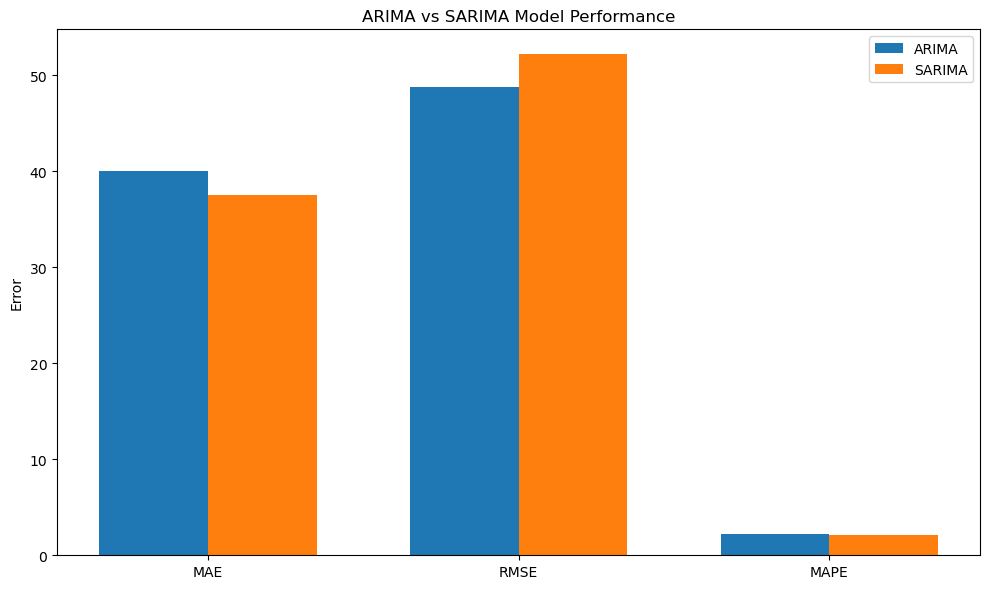

In [61]:
plt.figure(figsize=(10, 6))

x = np.arange(3)
width = 0.35

plt.bar(
    x - width / 2,
    [arima_mae, arima_rmse, arima_mape],
    width,
    label="ARIMA"
)

plt.bar(
    x + width / 2,
    [37.49, 52.15, 2.12],
    width,
    label="SARIMA"
)

plt.xticks(
    x,
    ["MAE", "RMSE", "MAPE"]
)

plt.title("ARIMA vs SARIMA Model Performance")
plt.ylabel("Error")
plt.legend()
plt.tight_layout()
plt.show()

In [62]:
final_summary = pd.DataFrame({
    "Metric": [
        "Historical Months",
        "Training Months",
        "Testing Months",
        "ARIMA MAPE (%)",
        "SARIMA MAPE (%)",
        "2026 Predicted Demand",
        "2026 Safety Stock",
        "2026 Recommended Stock"
    ],
    "Value": [
        len(forecast_data),
        len(train_data),
        len(test_data),
        round(arima_mape, 2),
        2.12,
        total_predicted,
        total_safety_stock,
        total_recommended
    ]
})

final_summary

,Metric,Value
0,Historical Months,48.00
1,Training Months,36.00
2,Testing Months,12.00
3,ARIMA MAPE (%),2.26
4,SARIMA MAPE (%),2.12
5,2026 Predicted Demand,21591.00
6,2026 Safety Stock,2158.00
7,2026 Recommended Stock,23749.00


In [63]:
final_summary.to_csv(
    "data/final_project_summary.csv",
    index=False
)

print("Final project summary saved successfully!")

Final project summary saved successfully!


In [64]:
import os

folders = [
    "data",
    "models",
    "graphs",
    "src"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [65]:
import pickle

with open("models/sarima_model.pkl", "wb") as file:
    pickle.dump(final_fit, file)

print("SARIMA model saved successfully!")

SARIMA model saved successfully!


In [66]:
import pickle

with open("models/arima_model.pkl", "wb") as file:
    pickle.dump(arima_fit, file)

print("ARIMA model saved successfully!")

ARIMA model saved successfully!


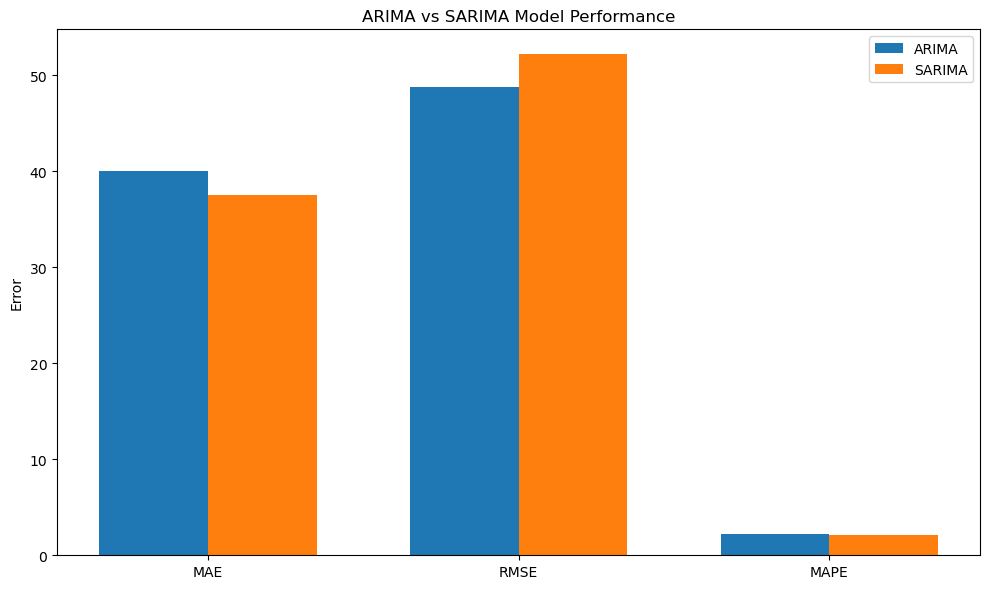

Model comparison graph saved successfully!


In [67]:
plt.figure(figsize=(10, 6))

x = np.arange(3)
width = 0.35

plt.bar(
    x - width / 2,
    [arima_mae, arima_rmse, arima_mape],
    width,
    label="ARIMA"
)

plt.bar(
    x + width / 2,
    [37.49, 52.15, 2.12],
    width,
    label="SARIMA"
)

plt.xticks(x, ["MAE", "RMSE", "MAPE"])
plt.title("ARIMA vs SARIMA Model Performance")
plt.ylabel("Error")
plt.legend()
plt.tight_layout()

plt.savefig(
    "graphs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison graph saved successfully!")

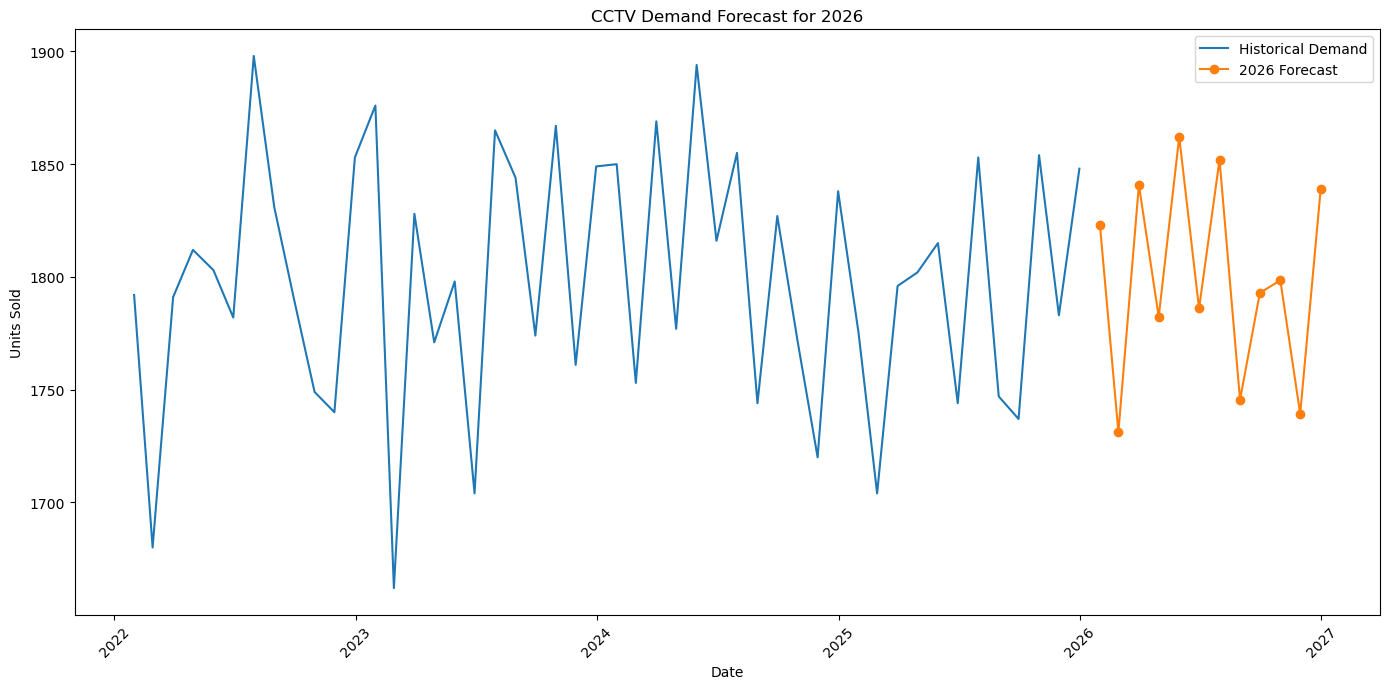

2026 forecast graph saved successfully!


In [68]:
plt.figure(figsize=(14, 7))

plt.plot(
    forecast_data.index,
    forecast_data.values,
    label="Historical Demand"
)

plt.plot(
    future_dates,
    future_forecast.values,
    marker="o",
    label="2026 Forecast"
)

plt.title("CCTV Demand Forecast for 2026")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "graphs/forecast_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("2026 forecast graph saved successfully!")

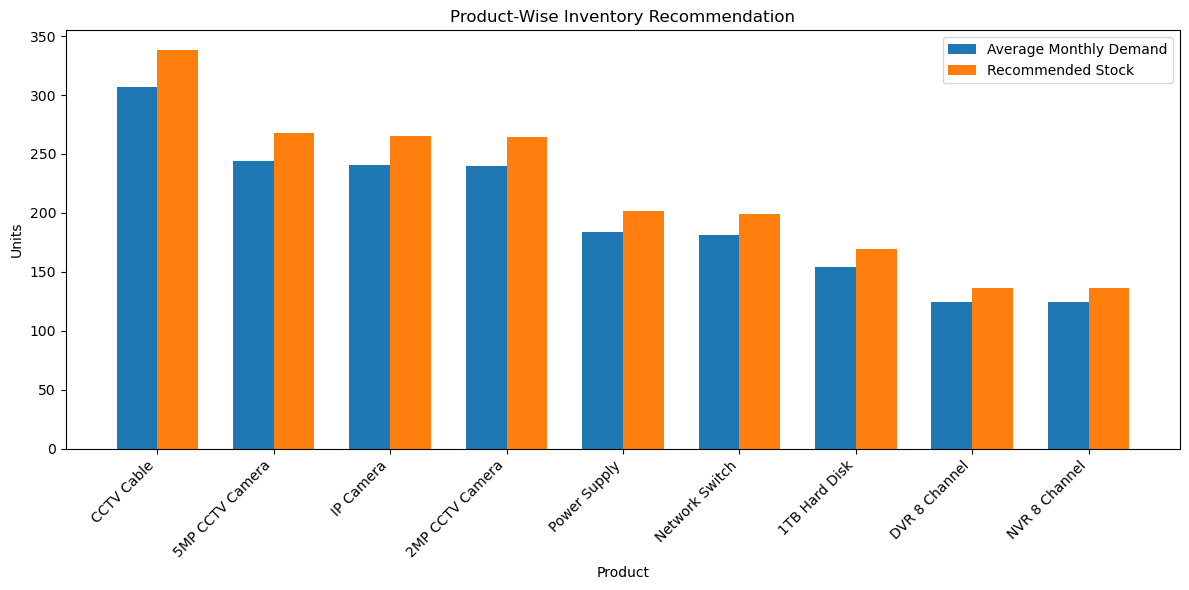

Product inventory graph saved successfully!


In [69]:
plt.figure(figsize=(12, 6))

x = np.arange(len(product_inventory))
width = 0.35

plt.bar(
    x - width / 2,
    product_inventory["Average_Monthly_Demand"],
    width,
    label="Average Monthly Demand"
)

plt.bar(
    x + width / 2,
    product_inventory["Recommended_Stock"],
    width,
    label="Recommended Stock"
)

plt.title("Product-Wise Inventory Recommendation")
plt.xlabel("Product")
plt.ylabel("Units")
plt.xticks(
    x,
    product_inventory["Product"],
    rotation=45,
    ha="right"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    "graphs/product_inventory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Product inventory graph saved successfully!")

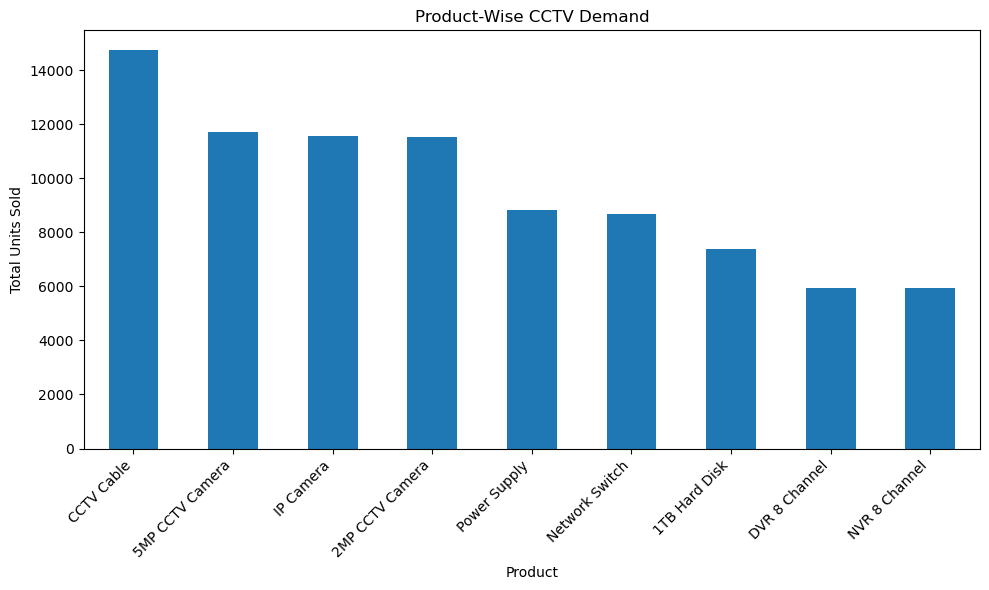

Product demand graph saved successfully!


In [70]:
plt.figure(figsize=(10, 6))

product_summary.plot(kind="bar")

plt.title("Product-Wise CCTV Demand")
plt.xlabel("Product")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "graphs/product_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Product demand graph saved successfully!")

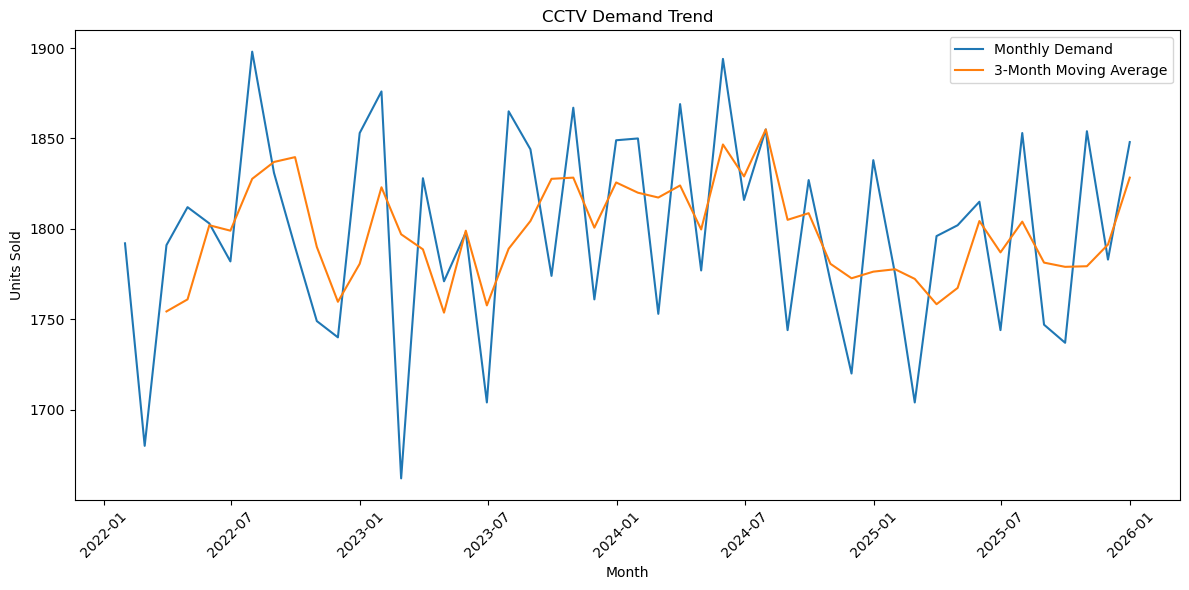

Monthly demand trend graph saved successfully!


In [71]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_demand,
    label="Monthly Demand"
)

plt.plot(
    moving_average,
    label="3-Month Moving Average"
)

plt.title("CCTV Demand Trend")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "graphs/monthly_demand_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monthly demand trend graph saved successfully!")

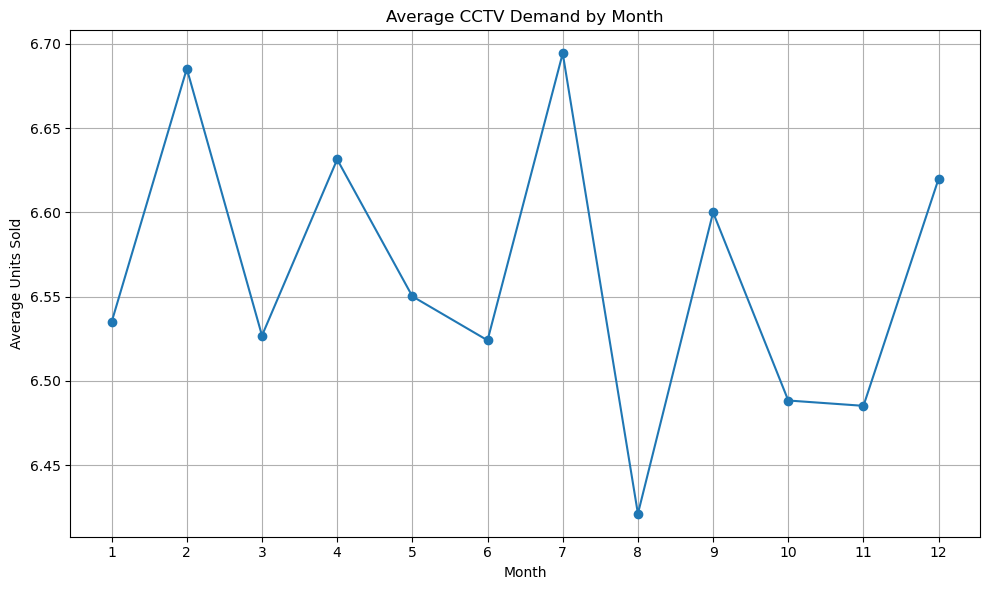

Seasonality graph saved successfully!


In [72]:
plt.figure(figsize=(10, 6))

plt.plot(
    monthly_seasonality.index,
    monthly_seasonality.values,
    marker="o"
)

plt.title("Average CCTV Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "graphs/monthly_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Seasonality graph saved successfully!")

In [73]:
import os

print("DATA FILES")
print("----------------")
for file in os.listdir("data"):
    print(file)

print("\nMODEL FILES")
print("----------------")
for file in os.listdir("models"):
    print(file)

print("\nGRAPH FILES")
print("----------------")
for file in os.listdir("graphs"):
    print(file)

DATA FILES
----------------
.ipynb_checkpoints
cctv_demand_data.csv
final_project_summary.csv
forecast_2026.csv
inventory_recommendation_2026.csv
product_inventory_recommendation.csv

MODEL FILES
----------------
arima_model.pkl
sarima_model.pkl

GRAPH FILES
----------------
forecast_2026.png
model_comparison.png
monthly_demand_trend.png
monthly_seasonality.png
product_demand.png
product_inventory.png


In [74]:
cctv_data = pd.read_csv(
    "data/cctv_demand_data.csv"
)

cctv_data["Date"] = pd.to_datetime(
    cctv_data["Date"]
)

print("Original project dataset loaded successfully!")
print("Shape:", cctv_data.shape)

Original project dataset loaded successfully!
Shape: (13149, 4)


# CCTV Equipment Demand Forecasting and Inventory Management System

## 1. Introduction

The CCTV industry requires proper demand forecasting and inventory planning to ensure that required equipment is available when needed. This project uses historical CCTV sales data and time-series forecasting techniques to predict future demand.

The system analyzes CCTV equipment demand and provides inventory recommendations using forecasting models.

## 2. Problem Statement

CCTV companies need to maintain sufficient stock of cameras, DVRs, NVRs, hard disks, cables and other equipment. Excess inventory can increase storage costs, while insufficient inventory can lead to stock shortages.

The proposed system uses data analysis and machine learning/time-series techniques to forecast demand and support inventory management.

## 3. Objectives

- Analyze historical CCTV equipment demand.
- Identify demand trends and seasonal patterns.
- Forecast future CCTV demand.
- Compare ARIMA and SARIMA models.
- Calculate safety stock.
- Generate recommended inventory levels.
- Provide visual reports for decision support.

## 4. Technologies Used

- Python
- Anaconda
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Statsmodels

## 5. Dataset

The dataset contains:

- Date
- Product
- Units Sold
- Support Requests

The dataset contains CCTV equipment from 2022 to 2025 and is simulated for academic purposes.

## 6. Products

- 2MP CCTV Camera
- 5MP CCTV Camera
- IP Camera
- DVR 8 Channel
- NVR 8 Channel
- 1TB Hard Disk
- Power Supply
- Network Switch
- CCTV Cable

## 7. Methodology

The project follows these stages:

1. Dataset creation
2. Data preprocessing
3. Exploratory Data Analysis
4. Demand aggregation
5. Time-series analysis
6. Train-test splitting
7. ARIMA forecasting
8. SARIMA forecasting
9. Model evaluation
10. Future demand forecasting
11. Inventory recommendation

## 8. Models

### ARIMA

ARIMA is used as a baseline time-series forecasting model.

### SARIMA

SARIMA extends ARIMA by incorporating seasonal behavior into the forecasting process.

## 9. Model Evaluation

The models are evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Percentage Error (MAPE)

## 10. Inventory Management

The system calculates safety stock using 10% of the forecast/average demand.

Recommended Stock:

Recommended Stock = Demand + Safety Stock

## 11. Expected Outcome

The system provides:

- Historical demand analysis
- Demand trend visualization
- Seasonal analysis
- Forecasted future demand
- Product-wise inventory recommendations
- Model performance comparison

## 12. Conclusion

The project demonstrates how data science and time-series forecasting can be applied to CCTV equipment demand planning and inventory management. The system provides a structured approach for analyzing demand and supporting inventory-related decisions.

# ABSTRACT

The "CCTV Equipment Demand Forecasting and Inventory Management System" is a data science-based project developed to analyze and forecast the demand for CCTV equipment. The system uses historical sales data containing product information, units sold, and technical support requests.

Data preprocessing and exploratory data analysis are performed to identify demand trends and seasonal patterns. Time-series forecasting models, including ARIMA and SARIMA, are applied to predict future CCTV equipment demand. The performance of the models is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

The system also calculates safety stock and recommended inventory levels based on predicted demand. This helps demonstrate how demand forecasting can support inventory planning and reduce the risk of insufficient or excessive stock.

The project is implemented using Python, Pandas, NumPy, Matplotlib, Scikit-learn, Statsmodels, Anaconda, and Jupyter Notebook. The dataset used in the project is simulated for academic purposes.

In [76]:
import os

print("Project files:")
for root, dirs, files in os.walk("."):
    for file in files:
        if not file.startswith("."):
            print(os.path.join(root, file))

Project files:
.\01_Data_Exploration.ipynb
.\README.md
.\.ipynb_checkpoints\01_Data_Exploration-checkpoint.ipynb
.\.ipynb_checkpoints\README-checkpoint.md
.\data\cctv_demand_data.csv
.\data\final_project_summary.csv
.\data\forecast_2026.csv
.\data\inventory_recommendation_2026.csv
.\data\product_inventory_recommendation.csv
.\data\.ipynb_checkpoints\cctv_demand_data-checkpoint.csv
.\graphs\forecast_2026.png
.\graphs\model_comparison.png
.\graphs\monthly_demand_trend.png
.\graphs\monthly_seasonality.png
.\graphs\product_demand.png
.\graphs\product_inventory.png
.\models\arima_model.pkl
.\models\sarima_model.pkl


In [78]:
# Final project verification

print("===== FINAL PROJECT VERIFICATION =====")

print("\nDataset:")
print("Rows:", len(cctv_data))
print("Columns:", cctv_data.shape[1])
print("Date Range:", cctv_data["Date"].min().date(), "to", cctv_data["Date"].max().date())

print("\nForecast:")
print("Forecast Months:", len(forecast_table))
print("2026 Predicted Demand:", total_predicted)

print("\nInventory:")
print("Safety Stock:", total_safety_stock)
print("Recommended Stock:", total_recommended)

print("\nModels:")
print("ARIMA MAPE:", round(arima_mape, 2), "%")
print("SARIMA MAPE:", 2.12, "%")

print("\n===== PROJECT VERIFICATION COMPLETE =====")

===== FINAL PROJECT VERIFICATION =====

Dataset:
Rows: 13149
Columns: 4
Date Range: 2022-01-01 to 2025-12-31

Forecast:
Forecast Months: 12
2026 Predicted Demand: 21591

Inventory:
Safety Stock: 2158
Recommended Stock: 23749

Models:
ARIMA MAPE: 2.26 %
SARIMA MAPE: 2.12 %

===== PROJECT VERIFICATION COMPLETE =====
